[← Previous: Data preparation](01_data_preparation.ipynb)

# Exploratory data analysis

## Class distribution

We examine face-label frequencies over the supplied training, validation, and test splits, using the reviewed class-name mapping described in data preparation. Counts refer to faces, not feature instances: one machining feature can contribute several faces. Stock denotes the remaining unmachined faces.

In [1]:
%matplotlib inline
%run scripts/eda_class_distribution.py
initialize_eda()

### Machining-feature classes

![Machining-feature reference shapes, with the 15 original MFCAD feature types outlined](../figures/machining-feature-classes-bordered.svg)

*Machining-feature reference shapes, adapted from Ma and Yang (2024), [Figure 8](https://www.nature.com/articles/s41598-024-61443-2/figures/8), under CC BY 4.0. The MFCAD++ diagram adds nine feature types with rounded geometry to the original MFCAD label set of 15 machining-feature classes plus stock. The red border marks the 15 original feature types used by both the UV-Net paper and our experiments. Stock denotes the remaining unmachined faces and is not shown as a separate feature.*

### Overall class distribution

We group the 16 labels by feature type and profile shape to compare their face counts. The table gives each class’s share of all labelled faces.

,Feature type,Shape,Extent,Faces,Percent
label,,,,,
stock,Stock,Other / not specified,,102396,29.296764
rectangular_pocket,Pocket,Rectangular,Blind,23340,6.677863
triangular_pocket,Pocket,Triangular,Blind,18756,5.366324
6sides_pocket,Pocket,Six-sided,Blind,32725,9.363028
rectangular_passage,Passage,Rectangular,Through,21792,6.234961
triangular_passage,Passage,Triangular,Through,15870,4.540604
6sides_passage,Passage,Six-sided,Through,32941,9.424828
rectangular_blind_slot,Slot,Rectangular,Blind,19160,5.481913
rectangular_through_slot,Slot,Rectangular,Through,14406,4.121735


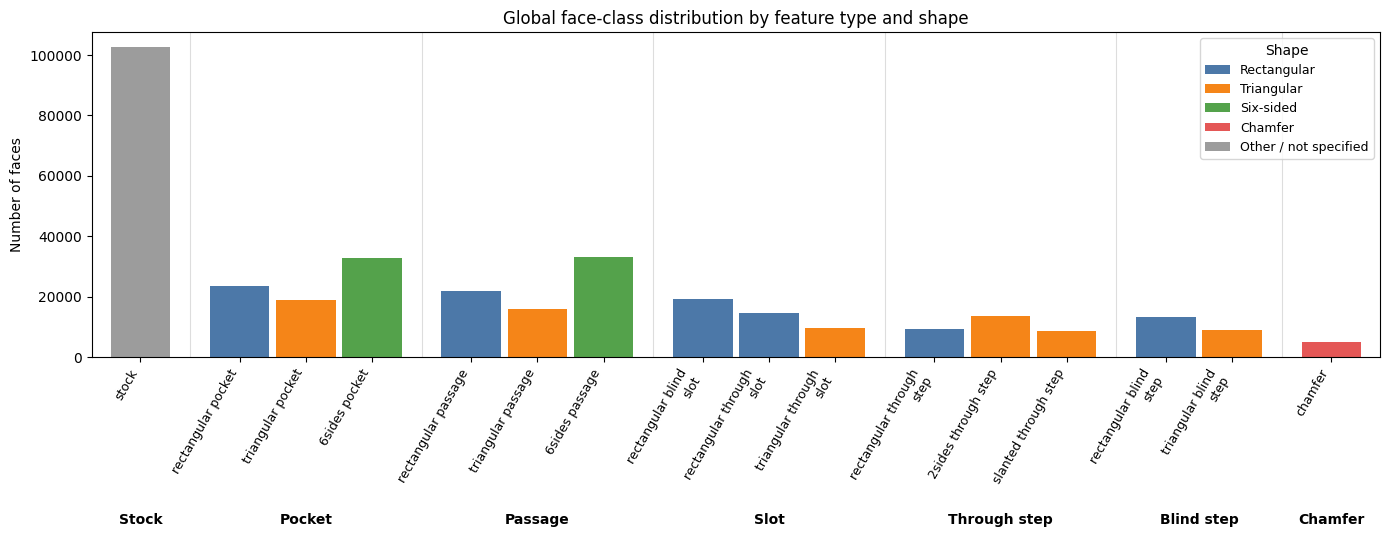

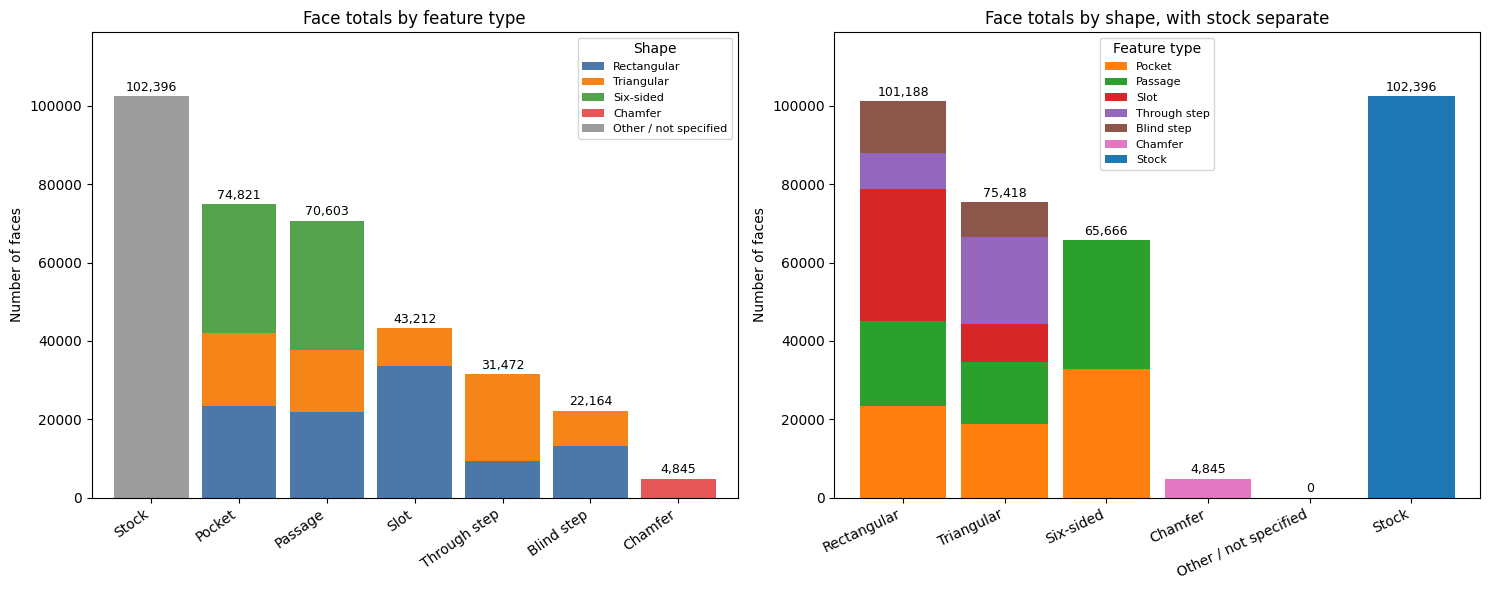

In [2]:
global_distribution()

Stock is the largest class, accounting for 29.3% of labelled faces. The remaining classes each account for between 1.4% and 9.4%. Rectangular and triangular profiles predominate among the machining-feature faces, with a smaller share of six-sided profiles.

### Number of machining-feature classes per solid

A machining operation can generate several faces, so face counts do not directly indicate the number of operations. We use the number of distinct machining-feature labels as a rough proxy for the variety of operations represented in each solid. We exclude stock because it is not a machining operation.

,count,mean,std,min,25%,50%,75%,max
Distinct machining-feature classes per solid,15461.0,3.649441,0.905923,1.0,3.0,4.0,4.0,5.0


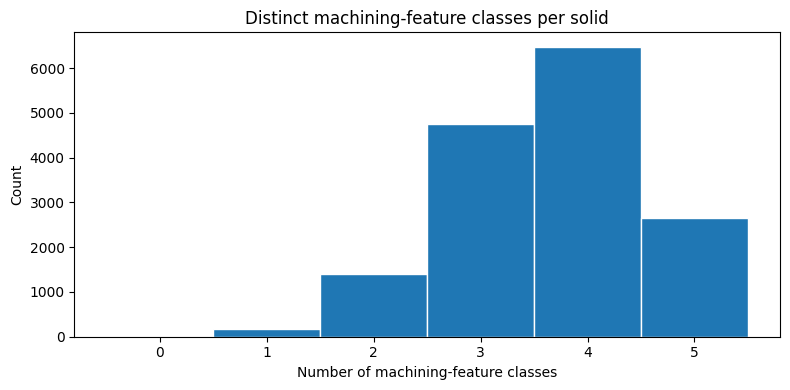

In [3]:
classes_per_solid()

Solids contain between one and five distinct machining-feature classes, with four the most common.

### Stock proportion

We distinguish the overall stock share from the distribution of stock proportions across individual solids.

,Faces,Percent
Stock,102396,29.296764
Other classes,247117,70.703236


,count,mean,std,min,25%,50%,75%,max
Stock fraction per model,15461.0,0.309968,0.084876,0.101695,0.25,0.3,0.352941,0.75


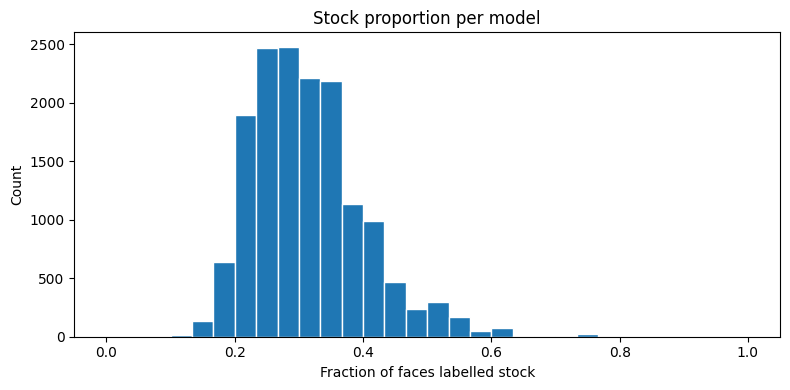

In [4]:
stock_distribution()

### Class distribution across splits

Raw counts show the number of faces available for each class. Within-split percentages allow comparison despite the different split sizes.

split,train,validation,test
label,,,
stock,61389,20449,20558
rectangular_pocket,14025,4645,4670
triangular_pocket,11356,3828,3572
6sides_pocket,19705,6804,6216
rectangular_passage,13077,4390,4325
triangular_passage,9605,2985,3280
6sides_passage,19859,6804,6278
rectangular_blind_slot,11556,3816,3788
rectangular_through_slot,8508,2883,3015


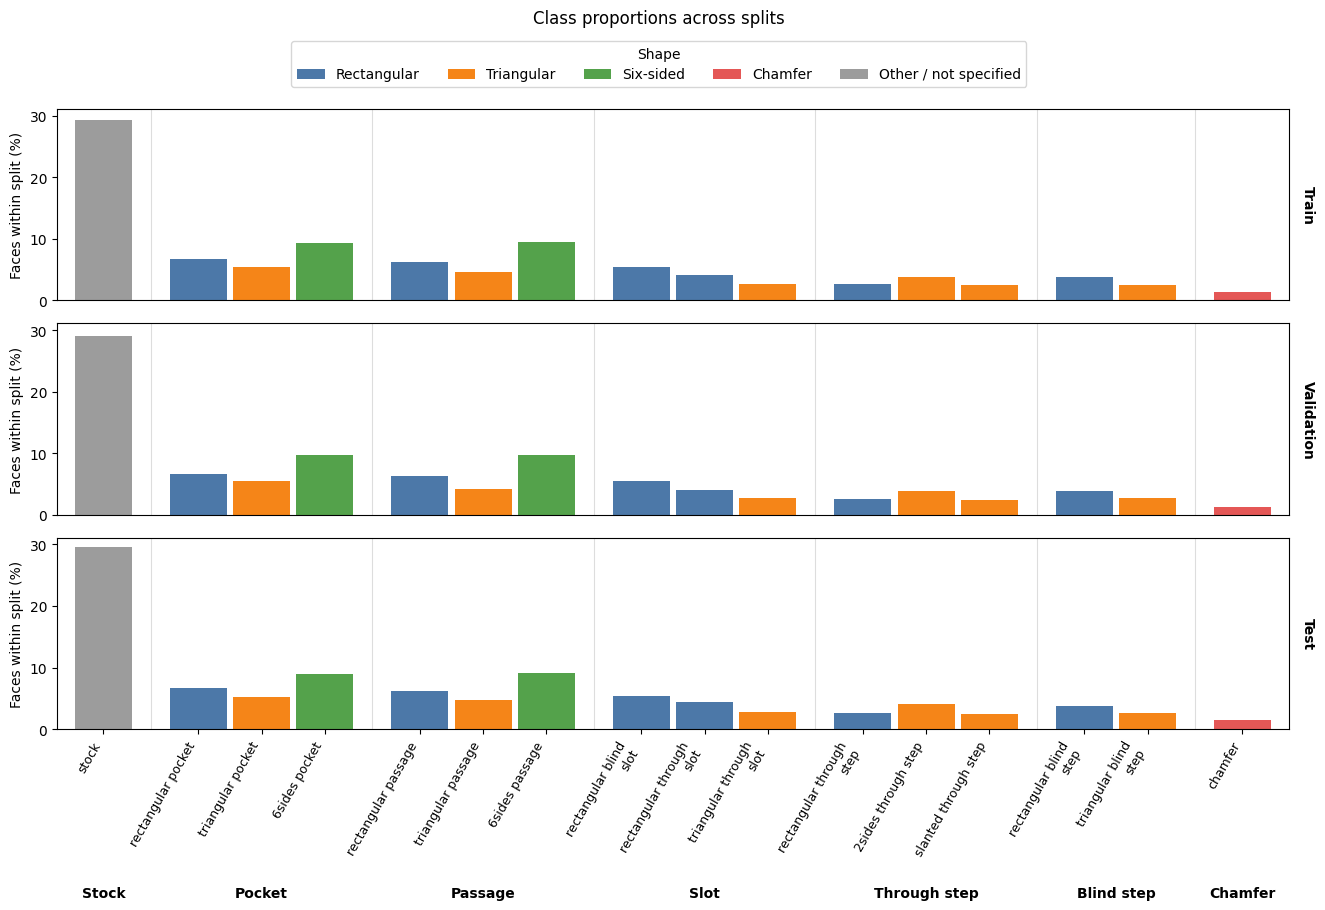

In [5]:
split_distribution()

Class proportions are similar across the three splits: the largest difference for any class is approximately 0.73 percentage points. This supports comparing models under a broadly consistent class distribution.

## Geometry

We examine simple geometric properties available in the surface grids: face extent and orientation. These describe potential cues for the geometry model, rather than establishing which cues a trained model uses.

### Flatness validation

For each face, we normalize the valid sampled normals and compute their minimum dot product with the normalized mean normal:

$$d_{\min}=\min_i\left(\hat{\mathbf n}_i\cdot\frac{\sum_j\hat{\mathbf n}_j}{\left\|\sum_j\hat{\mathbf n}_j\right\|}\right).$$

A value of 1 indicates constant normal direction. All 349,513 faces satisfy $d_{\min}\approx 1$ within an absolute tolerance of $10^{-6}$, consistent with the dataset’s planar faces.

In [6]:
%run scripts/eda_geometry.py
geometry_faces = geometry_statistics()
geometry_summary(geometry_faces)

Flat faces: 349,513 / 349,513
Non-flat faces: 0
Undefined normals: 0


<Figure size 640x480 with 0 Axes>

### Face spans by class

Using only samples inside the trimming mask, we measure each face’s coordinate range along X, Y, and Z. We retain the shortest non-zero range and the longest range. These are axis-aligned bounding-box spans in the supplied coordinates, rather than intrinsic face dimensions. Boxes show the interquartile range, red lines the median, and whiskers the 5th and 95th percentiles; tails are omitted.

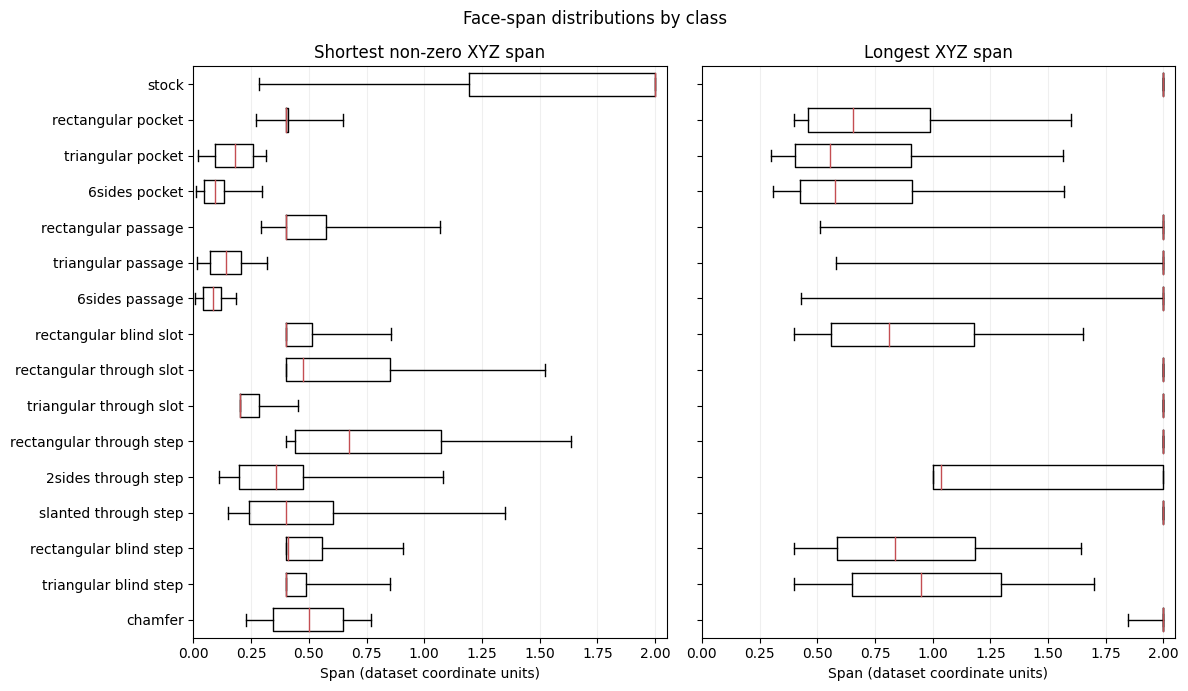

In [7]:
face_span_distributions(geometry_faces)

By design, through features (passages, through slots, and through steps) extend across the stock, whose full span is 2 in the normalized coordinates. An uninterrupted face extending along the through direction therefore has a longest span of 2; intersections with other features can shorten or split that face, producing smaller spans. Stock faces also have median shortest and longest spans of 2, whereas pocket faces tend to have smaller longest spans. These differences provide simple size cues, although the distributions overlap.

### Face orientation by class

We measure the proportion of faces whose unit normal aligns with any primary axis, including both signs, using an absolute tolerance of $10^{-6}$.

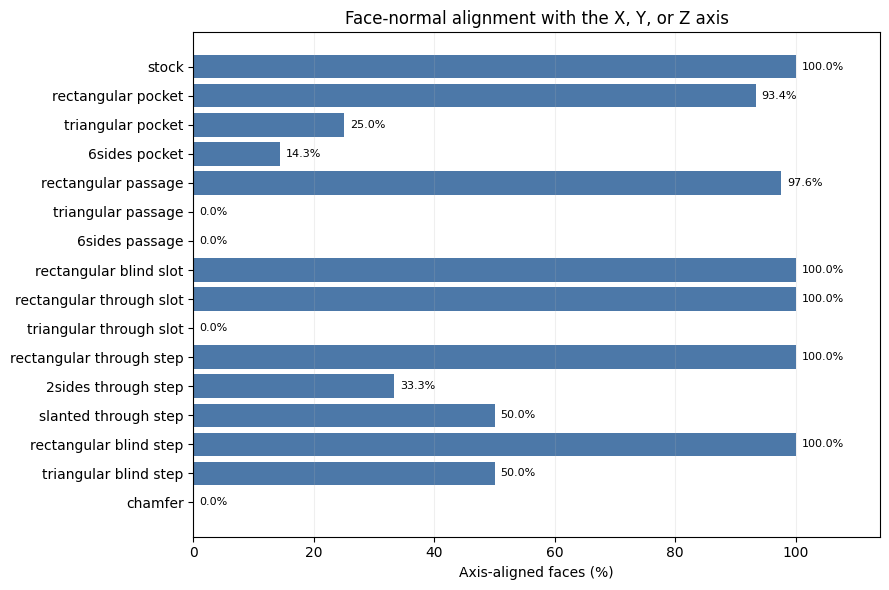

In [8]:
face_axis_alignment(geometry_faces)

The synthetic construction produces simple orientation patterns that a model could exploit: rectangular-feature faces are predominantly axis-aligned, while chamfer faces are inclined. Triangular and six-sided pockets have axis-aligned shares of 25% and 14.3%, respectively, consistent with one aligned bottom face among three or six inclined walls.

## Graph structure

### Faces and edges per solid

Each face is a graph node. We count each B-rep boundary edge once, combining its two reciprocal directed graph entries while retaining distinct boundaries between the same pair of faces.

,min,median,mean,max
faces,8.0,22.0,22.606106,59.0
edges,18.0,60.0,59.981631,189.0


<Figure size 640x480 with 0 Axes>

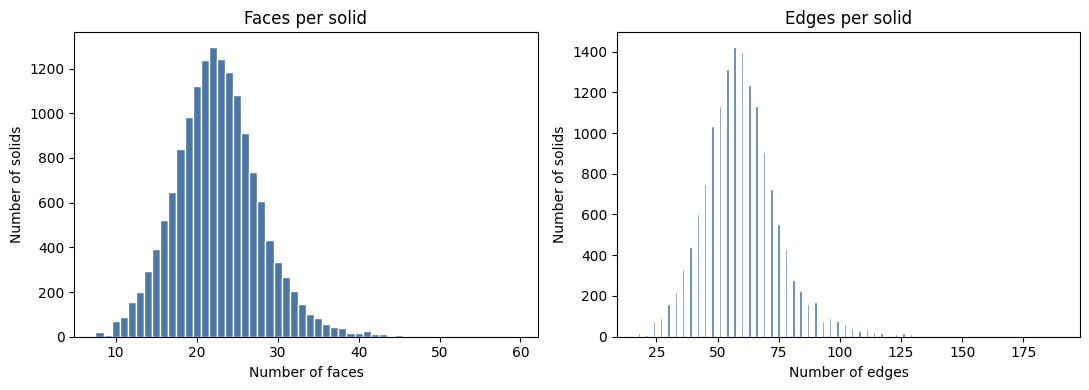

In [9]:
%run scripts/eda_graph.py
graph_stats = graph_statistics()
graph_sizes(graph_stats)

Solids contain a mean of 22.6 faces and 60.0 boundary edges. Face counts range from 8 to 59, and edge counts from 18 to 189.

### Node degree of machining-feature faces

We plot the degree distribution for non-stock faces, counting the B-rep boundaries incident to each face.

,min,median,mean,max
Non-stock face degree,3.0,4.0,4.197485,18.0


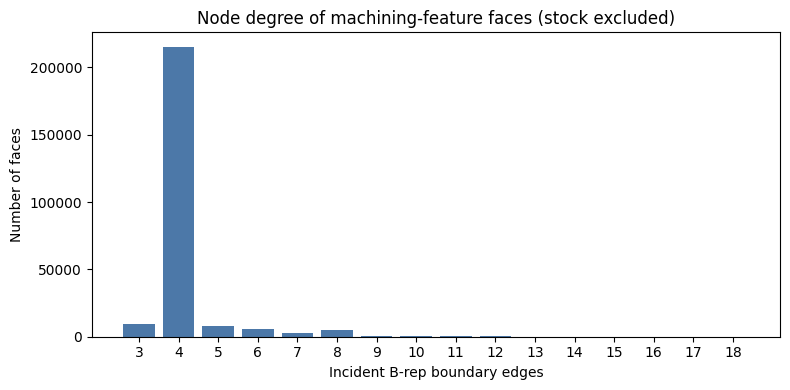

Non-stock: 215,194 / 247,117 faces have degree 4 (87.1%).
Stock: 28,241 / 102,396 faces have degree 4 (27.6%).


In [10]:
nonstock_node_degrees(graph_stats)

Degree 4 accounts for 87.1% of machining-feature faces, reflecting how these operations predominantly generate rectangular faces. The per-class breakdown below shows how this relates to individual feature structures.

### Maximum node degree per solid

,count,mean,std,min,25%,50%,75%,max
Maximum non-stock degree per solid,15461.0,5.350818,1.817465,4.0,4.0,5.0,6.0,18.0


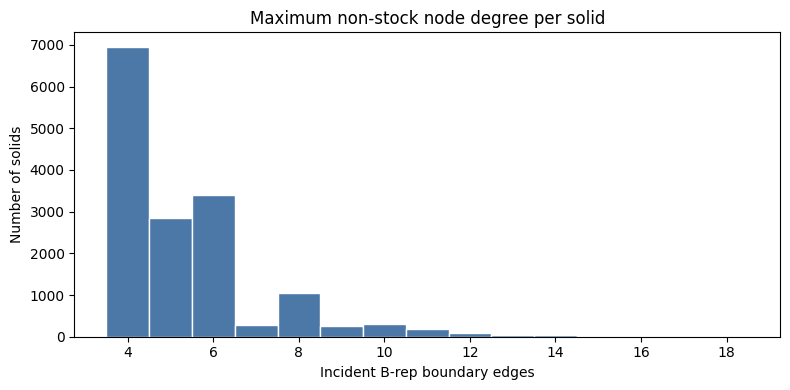

In [11]:
maximum_node_degrees(graph_stats)

### Node degree by class

We compare the percentages of non-stock faces at degrees 3, 4, 5, 6, and 8, using the reviewed class names. Each percentage is relative to all faces of that class; only selected degrees are shown, so rows need not sum to 100%.

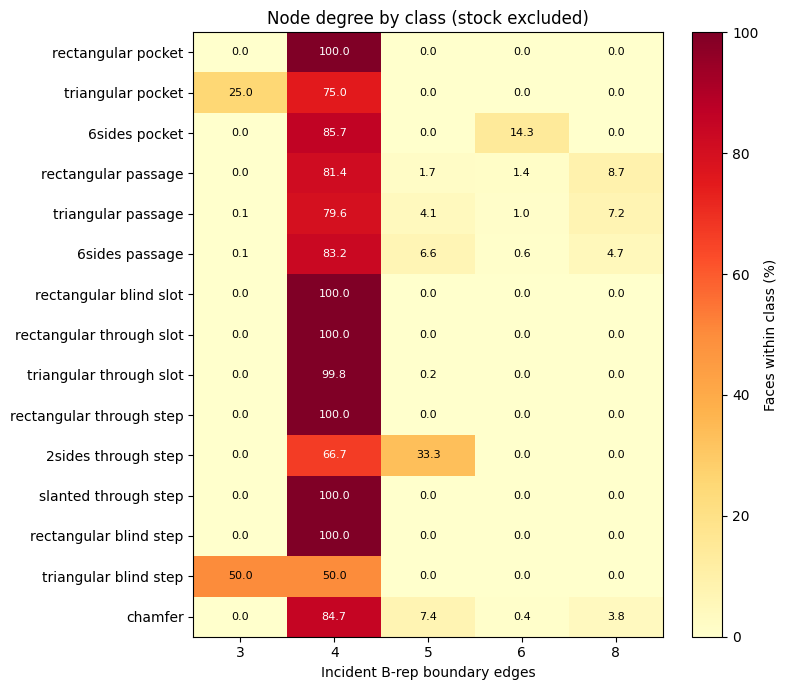

In [12]:
node_degree_by_class(graph_stats)

Degree 4 is expected for a rectangular face, regardless of the machining operation that produced it. For example, a triangular pocket has one triangular bottom and three rectangular walls, explaining its 25% degree-3 and 75% degree-4 faces. A six-sided pocket has one hexagonal bottom and six rectangular walls, giving 14.3% degree-6 and 85.7% degree-4 faces. Passage and chamfer faces show more varied degrees, most likely because intersections alter their boundaries.

### Shortest-path diameter

The graph diameter is the largest shortest-path distance between any two faces in a solid.

,count,mean,std,min,25%,50%,75%,max
Shortest-path diameter,15461.0,3.952073,0.989318,2.0,3.0,4.0,5.0,6.0


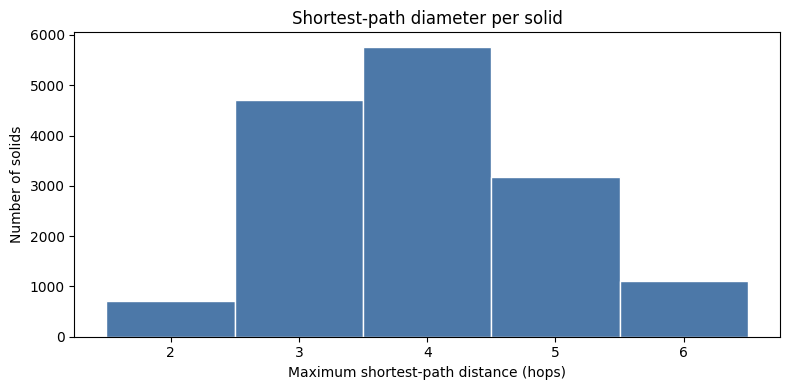

In [13]:
topology_stats = topology_statistics()
graph_diameters(topology_stats)

Graph diameters range from two to six hops, with four the most common.

### Face reachability within N hops

Like diameter, reachability describes how far information can travel through the graph. Diameter gives one maximum distance per solid; here, the unit of observation is a starting face.

For each starting face, we measure the percentage of other faces reachable within N hops. Each face contributes one observation; the starting face is excluded from the denominator. Solids already fully covered remain at 100% for later hops.

,count,mean,std,min,25%,50%,75%,max
Hops,,,,,,,,
1,349513.0,24.342499,13.600785,5.357143,16.000000,19.047619,26.666666,96.551727
2,349513.0,72.307724,21.873909,9.523809,56.521740,73.913040,93.333336,100.000000
3,349513.0,95.294357,10.568341,20.454546,95.454544,100.000000,100.000000,100.000000
4,349513.0,99.558868,2.426001,38.461540,100.000000,100.000000,100.000000,100.000000
5,349513.0,99.970528,0.365628,87.500000,100.000000,100.000000,100.000000,100.000000
6,349513.0,100.000000,0.000000,100.000000,100.000000,100.000000,100.000000,100.000000


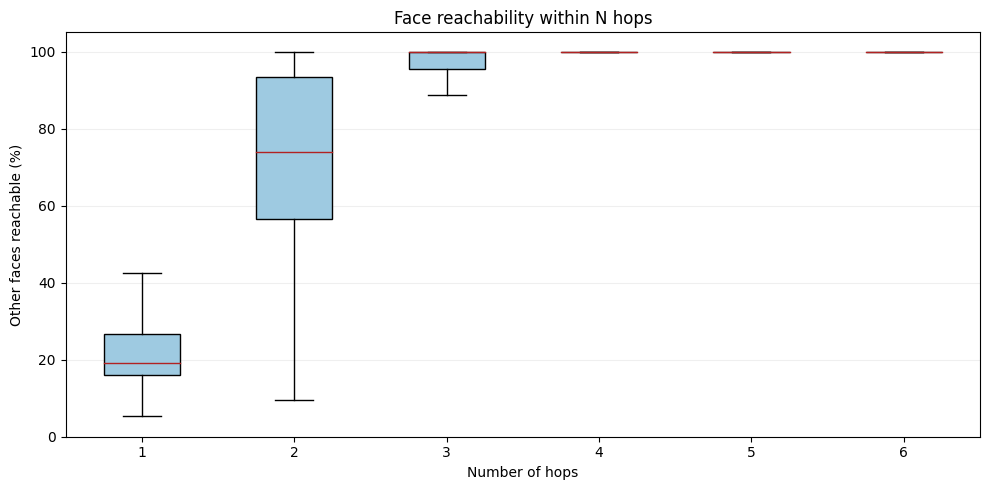

In [14]:
face_reachability(topology_stats)

The median face reaches 19.0% of the other faces in one hop and 73.9% in two hops; at three hops, median coverage reaches 100%.

---

[← Previous: Data preparation](01_data_preparation.ipynb) | [Next: Modelling →](03_modelling.ipynb)